# 01 · Data exploration — QM9 dipole moments
Run `python src/build_dataset.py` and `python src/make_splits.py` first. This notebook only *reads* the processed table; it fits nothing.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
from config import FEATURES_PATH, RESULTS, SPLITS
df = pd.read_parquet(FEATURES_PATH)
print(df.shape)
df[['mol_id','smiles','mu','comp_natoms','comp_nheavy']].head()

(131970, 262)


,mol_id,smiles,mu,comp_natoms,comp_nheavy
0,gdb_1,C,0.0000,5.0,1.0
1,gdb_2,N,1.6256,4.0,1.0
2,gdb_3,O,1.8511,3.0,1.0
3,gdb_4,C#C,0.0000,4.0,2.0
4,gdb_5,C#N,2.8937,3.0,2.0


## One row = one molecule
Each row is one of the 131,970 QM9 molecules that RDKit could parse. The target `mu` is the magnitude of the DFT (B3LYP/6-31G(2df,p)) dipole moment in Debye.

In [2]:
q = json.loads((RESULTS/'data_quality.json').read_text())
{k: v for k, v in q.items() if not isinstance(v, (list, dict))}

{'n_sdf_blocks': 133885,
 'n_label_rows': 133885,
 'n_rdkit_failures': 1915,
 'mu_failed_mean': 2.4981744647519584,
 'mu_failed_median': 2.1936,
 'mu_kept_mean': 2.709053743274987,
 'mu_kept_median': 2.5056,
 'n_kept': 131970,
 'n_missing_labels': 0,
 'n_features': 256,
 'n_mu_exactly_zero': 45,
 'n_mu_below_0.1': 921,
 'n_mu_above_10': 280,
 'mu_skew': 1.4560728158503724,
 'n_rows_sharing_isomeric_smiles': 536,
 'n_rows_sharing_2d_graph': 665,
 'n_2d_graphs_with_duplicates': 326,
 'median_mu_spread_within_same_2d_graph': 0.0006000000000001907,
 'max_mu_spread_within_same_2d_graph': 5.239000000000001,
 'n_acyclic': 14127,
 'n_unique_scaffolds': 14712}

## Target distribution
Right-skewed (skew ≈ 1.46), 921 molecules below 0.1 D (symmetric), 280 above 10 D (mostly zwitterions).

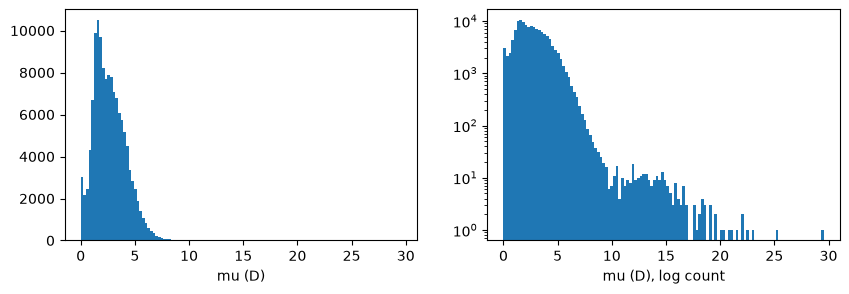

count    131970.000000
mean          2.709054
std           1.535051
min           0.000000
25%           1.585400
50%           2.505600
75%           3.642900
max          29.556400
Name: mu, dtype: float64

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(df.mu, bins=120); ax[0].set_xlabel('mu (D)')
ax[1].hist(df.mu, bins=120, log=True); ax[1].set_xlabel('mu (D), log count')
plt.show()
df.mu.describe()

In [4]:
pd.DataFrame(q['top_mu_molecules'])

,mol_id,smiles,mu
0,gdb_123126,[NH3+]CCCCCC(=O)[O-],29.5564
1,gdb_121864,C[C@@H](CCC[NH3+])C(=O)[O-],25.2022
2,gdb_101807,[NH3+]C[C@@H](O)CCC(=O)[O-],22.9605
3,gdb_97476,[NH3+]CC#CC#CC(=O)[O-],22.6486
4,gdb_56343,N/C=[NH+]/CCCC(=O)[O-],21.9335
5,gdb_97458,N/C=[NH+]/CCCC(=O)[O-],21.9326
6,gdb_100457,[NH3+]C[C@@H](O)C#CC(=O)[O-],21.5120
7,gdb_130454,[NH3+]CCc1cc(=O)o[nH]1,20.9824
8,gdb_121600,C[NH2+]CCC(=O)C(=O)[O-],20.8468
9,gdb_130453,[NH-]c1nc(CC[NH3+])no1,20.3686


## Size of molecules
Most molecules have 9 heavy atoms, which is why the size-extrapolation split trains on ≤ 8 and tests on 9.

In [5]:
print(df.comp_nheavy.value_counts().sort_index())
df.groupby('comp_nheavy').mu.agg(['count','mean','std']).round(3)

comp_nheavy
1.0          3
2.0          5
3.0          9
4.0         31
5.0        126
6.0        608
7.0       3134
8.0      17894
9.0     108865
10.0      1226
11.0        63
12.0         6
Name: count, dtype: int64


,count,mean,std
comp_nheavy,,,
1.0,3,1.159,1.010
2.0,5,1.306,1.287
3.0,9,1.692,1.429
4.0,31,1.819,1.550
5.0,126,2.197,1.381
6.0,608,2.346,1.482
7.0,3134,2.472,1.399
8.0,17894,2.615,1.480
9.0,108865,2.726,1.543


## Does a cheap physical estimate carry signal?
`phys_gasteiger_dipole` = |Σ qᵢ rᵢ| with Gasteiger charges (from the bond graph, no DFT) and the 3D coordinates. It is not the DFT dipole, but it should correlate with it.

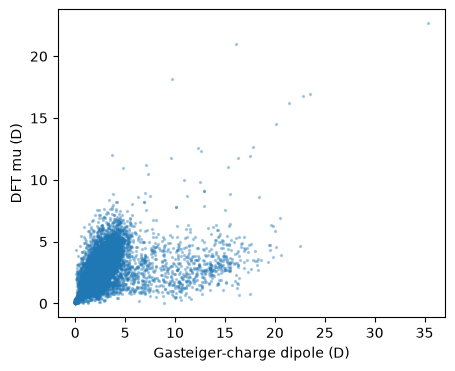

mu                       1.000
phys_gasteiger_dipole    0.530
phys_bond_dipole         0.361
q2_absmean               0.353
comp_nheavy              0.042
geo_cm00                 0.221
Name: mu, dtype: float64

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
s = df.sample(8000, random_state=0)
ax.scatter(s.phys_gasteiger_dipole, s.mu, s=2, alpha=0.3)
ax.set(xlabel='Gasteiger-charge dipole (D)', ylabel='DFT mu (D)'); plt.show()
df[['mu','phys_gasteiger_dipole','phys_bond_dipole','q2_absmean','comp_nheavy','geo_cm00']].corr(method='spearman')['mu'].round(3)

## Same 2D graph, different dipole
Some bond graphs occur more than once (stereo-isomers / conformers). Their dipoles can differ by several Debye, so a 2D-only model has irreducible error for them, and they are kept on one side of every random split.

In [7]:
d = df[df.smiles_2d.duplicated(keep=False)].groupby('smiles_2d').mu.agg(['count','min','max'])
d['spread'] = d['max'] - d['min']
d.sort_values('spread', ascending=False).head(10)

,count,min,max,spread
smiles_2d,,,,
CNc1[nH]ccc1O,2,0.6633,5.9023,5.2390
CCNc1[nH]ccc1O,2,0.6426,5.8159,5.1733
CNc1[nH]cc(C)c1O,2,0.7866,5.5114,4.7248
CNc1[nH]c(C)cc1O,2,0.9789,4.4049,3.4260
CNc1c(O)ccn1C,2,0.5687,3.8736,3.3049
CC12C3CC4CC3C1C42,3,0.2039,2.9968,2.7929
CC12C3CC4C(C3)C1C42,2,0.1105,2.7836,2.6731
Oc1ccn2c1NCC2,2,3.5201,5.9876,2.4675
OC12C3CC4C(C3)C1C42,2,1.2971,3.7203,2.4232


## Splits
All splits are fixed in `data/splits/splits.csv.gz` before any model is trained.

In [8]:
pd.DataFrame(json.loads((RESULTS/'split_summary.json').read_text())).T

,n_train,n_test,mu_mean_train,mu_mean_test,test_frac_acyclic,graph_overlap,scaffold_overlap_rows
random_s0,105576.0,26394.0,2.7101,2.7049,0.1081,0.0,21157.0
random_s1,105576.0,26394.0,2.7097,2.7065,0.1050,0.0,21265.0
random_s2,105576.0,26394.0,2.7099,2.7057,0.1082,0.0,21204.0
scaffold,105157.0,26813.0,2.7056,2.7227,0.0000,0.0,0.0
size_le8,21810.0,21773.0,2.5829,2.7240,0.0879,0.0,17172.0
size_control,21810.0,21773.0,2.7067,2.7240,0.0879,0.0,16539.0


## Why the other QM9 columns are not used as inputs
The property table also contains HOMO/LUMO, polarisability, energies, etc. They come out of the *same* DFT calculation as the dipole; using them would mean we already ran the calculation we are trying to skip. We never load them (`build_dataset.py` reads only `mol_id` and `mu`).